# 数据统计分析与质量检查（EDA）

**数据集**：由 `config/config.yaml` 的 `dataset.name` 决定（当前 Books，Amazon 5-core）  
**数据目录**：配置中的 `paths.processed_dir`（如 `data/processed/Books/`，含 `train` / `test`）

**目标**
1. 统计训练/测试集的基本分布：评分、用户活跃度、商品流行度、长尾、时间、文本；
2. 通过可视化判断数据质量与可用性；
3. 检查潜在问题：缺失、重复、非法值、训练/测试泄漏、冷启动与极端用户。

> 运行环境：conda 环境 `amazon-recsys`（Python 3.10）。图表与统计摘要保存到 `experiments/logs/eda/<数据集>/`（按数据集分目录，互不覆盖）。

## 1. 环境与数据加载

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import yaml

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")


def find_project(start: Path) -> Path:
    p = Path(start).resolve()
    for parent in [p, *p.parents]:
        if (parent / "config" / "config.yaml").exists():
            return parent
    return p


PROJECT = find_project(Path.cwd())
cfg = yaml.safe_load((PROJECT / "config" / "config.yaml").read_text(encoding="utf-8"))
DATASET = cfg["dataset"]["name"]
DATA = PROJECT / cfg["paths"]["processed_dir"]
# 每个数据集独立子目录，避免不同数据集的图表相互覆盖
FIG = PROJECT / "experiments" / "logs" / "eda" / DATASET
FIG.mkdir(parents=True, exist_ok=True)

font_family = ["Noto Sans CJK JP", "Noto Sans CJK SC", "Noto Serif CJK JP", "DejaVu Sans"]
plt.rcParams["font.sans-serif"] = font_family
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 120
sns.set_theme(style="whitegrid", font=font_family[0])

print("项目根目录:", PROJECT)
print("数据集:", DATASET)
print("数据目录:", DATA)
print("图表输出:", FIG)

项目根目录: /data2/malong/media_lab/amazon-recommender
数据集: Books
数据目录: /data2/malong/media_lab/amazon-recommender/data/processed/Books
图表输出: /data2/malong/media_lab/amazon-recommender/experiments/logs/eda/Books


In [2]:
train = pd.read_parquet(DATA / "train.parquet")
test = pd.read_parquet(DATA / "test.parquet")

print(f"train: {train.shape[0]:,d} 行 × {train.shape[1]} 列")
print(f"test : {test.shape[0]:,d} 行 × {test.shape[1]} 列")
print("\n字段类型:")
display(train.dtypes.to_frame("dtype").T)
display(train.head(2))

train: 7,142,099 行 × 11 列
test : 1,755,942 行 × 11 列

字段类型:


,user_id,item_id,rating,review_text,summary,timestamp,review_time,reviewer_name,helpful_no,helpful_yes,extra
dtype,string[python],string[python],int64,string[python],string[python],Int64,string[python],string[python],Int64,Int64,string[python]


,user_id,item_id,rating,review_text,summary,timestamp,review_time,reviewer_name,helpful_no,helpful_yes,extra
0,A000443821AD43TOGKNGZ,B0089PFDLY,4,Reading this book made me wonder what else cou...,Great book,1353369600,"11 20, 2012",Uluwehi,0,0,
1,A000443821AD43TOGKNGZ,0615598668,4,"When I started reading this book, I got so int...",Awesome book...,1374796800,"07 26, 2013",Uluwehi,0,0,


## 2. 数据质量检查

逐项检查缺失、非法评分、重复记录、空文本、时间戳异常，以及训练/测试是否存在同一 `(user_id, item_id)` 造成的泄漏。

In [3]:
def quality_report(df: pd.DataFrame, name: str) -> pd.DataFrame:
    rows = [
        ("样本数", len(df)),
        ("用户数", df.user_id.nunique()),
        ("商品数", df.item_id.nunique()),
        ("缺失 user_id", int(df.user_id.isna().sum())),
        ("缺失 item_id", int(df.item_id.isna().sum())),
        ("缺失 rating", int(df.rating.isna().sum())),
        ("非法评分(非1-5)", int((~df.rating.between(1, 5)).sum())),
        ("重复(user,item)", int(df.duplicated(["user_id", "item_id"]).sum())),
        ("空评论文本", int((df.review_text.str.len() == 0).sum())),
        ("空标题", int((df.summary.str.len() == 0).sum())),
        ("时间戳缺失", int(df.timestamp.isna().sum())),
        ("时间戳<=0", int((df.timestamp <= 0).sum())),
    ]
    return pd.DataFrame(rows, columns=["项目", name]).set_index("项目")


qr = quality_report(train, "train").join(quality_report(test, "test"))

leak = train[["user_id", "item_id"]].merge(
    test[["user_id", "item_id"]], on=["user_id", "item_id"], how="inner"
)
checks = pd.DataFrame({
    "指标": [
        "训练/测试 (user,item) 重叠",
        "仅在训练的用户",
        "仅在测试的用户",
        "训练集评分范围",
        "测试集评分范围",
    ],
    "值": [
        len(leak),
        len(set(train.user_id) - set(test.user_id)),
        len(set(test.user_id) - set(train.user_id)),
        f"{train.rating.min()} - {train.rating.max()}",
        f"{test.rating.min()} - {test.rating.max()}",
    ],
})

display(qr)
display(checks)

,train,test
项目,,
样本数,7142099,1755942
用户数,603668,603668
商品数,367965,318935
缺失 user_id,0,0
缺失 item_id,0,0
缺失 rating,0,0
非法评分(非1-5),0,0
"重复(user,item)",0,0
空评论文本,486,104


,指标,值
0,"训练/测试 (user,item) 重叠",0
1,仅在训练的用户,0
2,仅在测试的用户,0
3,训练集评分范围,1 - 5
4,测试集评分范围,1 - 5


**质量检查结论**：若上表缺失、非法评分、重复、泄漏均为 0，且训练/测试用户完全覆盖，则划分可用于后续建模。文本字段的空值率也会影响文本增强模型是否值得使用。

## 3. 基本统计与稀疏度

稀疏度 = 1 − 评分数 / (用户数 × 商品数)，反映用户-商品矩阵的填充比例。

In [4]:
def sparsity(df: pd.DataFrame) -> float:
    u, i, n = df.user_id.nunique(), df.item_id.nunique(), len(df)
    return 1 - n / (u * i)


summary = pd.DataFrame({
    "train": [
        len(train), train.user_id.nunique(), train.item_id.nunique(),
        round(sparsity(train), 6), round(train.rating.mean(), 4), round(train.rating.std(), 4),
    ],
    "test": [
        len(test), test.user_id.nunique(), test.item_id.nunique(),
        round(sparsity(test), 6), round(test.rating.mean(), 4), round(test.rating.std(), 4),
    ],
}, index=["记录数", "用户数", "商品数", "稀疏度", "评分均值", "评分标准差"])

display(summary)

,train,test
记录数,"7,142,099.0000","1,755,942.0000"
用户数,"603,668.0000","603,668.0000"
商品数,"367,965.0000","318,935.0000"
稀疏度,1.0000,1.0000
评分均值,4.2501,4.2494
评分标准差,1.0581,1.0562


## 4. 评分分布

对比训练集与测试集的 1–5 星占比，判断两者是否同分布。

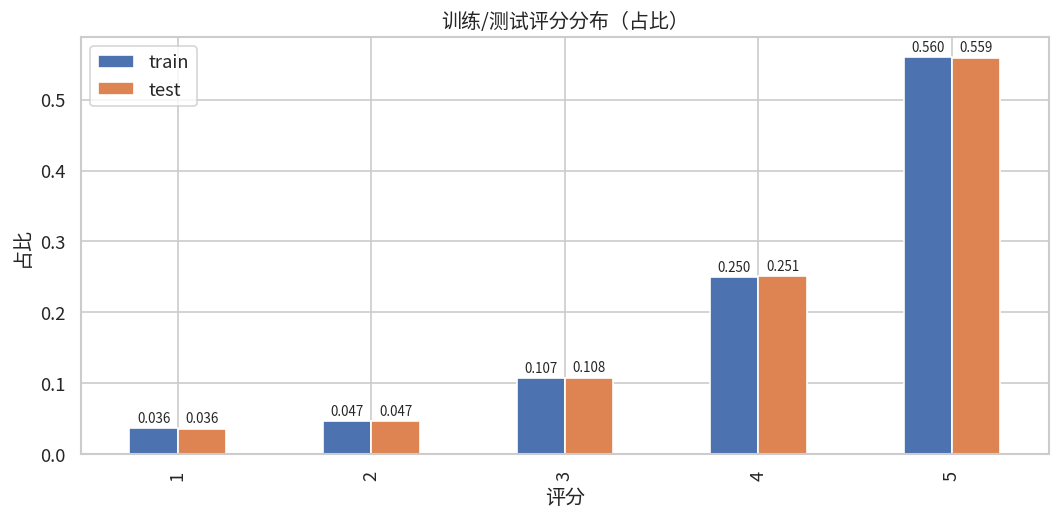

rating,1,2,3,4,5
train,0.0365,0.0466,0.1073,0.2496,0.5600
test,0.0360,0.0468,0.1077,0.2507,0.5588


In [5]:
rd = pd.DataFrame({
    "train": train.rating.value_counts(normalize=True).sort_index(),
    "test": test.rating.value_counts(normalize=True).sort_index(),
})

ax = rd.plot(kind="bar", figsize=(9, 4.5), color=["#4C72B0", "#DD8452"], edgecolor="white")
ax.set_title("训练/测试评分分布（占比）")
ax.set_xlabel("评分")
ax.set_ylabel("占比")
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=2, fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "01_rating_distribution.png", bbox_inches="tight", dpi=150)
plt.show()

display(rd.round(4).T)

## 5. 用户活跃度与商品流行度

采用对数坐标观察长尾程度：多数用户/商品交互很少，少数头部贡献大量评分。

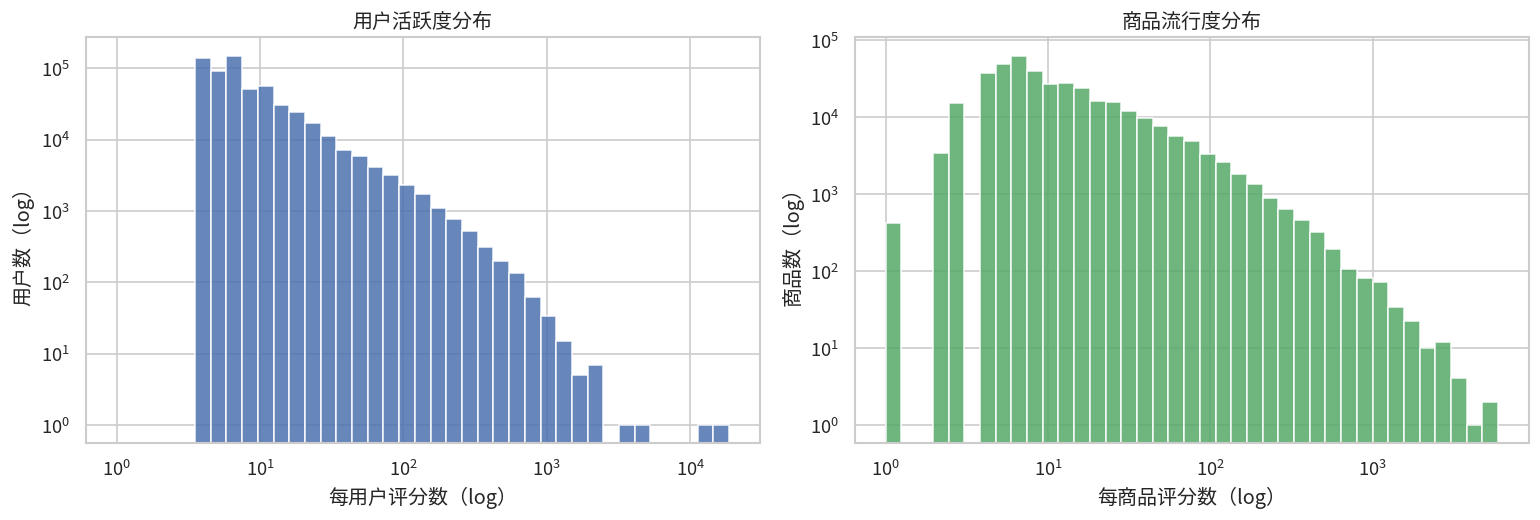

用户评分数分位数:
count   603,668.0000
mean         11.8300
std          41.4200
min           4.0000
50%           6.0000
90%          19.0000
99%         105.0000
max      18,578.0000
dtype: float64

商品评分数分位数:
count   367,965.0000
mean         19.4100
std          53.3100
min           1.0000
50%           8.0000
90%          38.0000
99%         182.0000
max       5,946.0000
dtype: float64


In [6]:
user_counts = train.groupby("user_id").size()
item_counts = train.groupby("item_id").size()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(user_counts, bins=np.logspace(0, np.log10(user_counts.max() + 1), 40),
             color="#4C72B0", alpha=0.85)
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_title("用户活跃度分布")
axes[0].set_xlabel("每用户评分数（log）")
axes[0].set_ylabel("用户数（log）")

axes[1].hist(item_counts, bins=np.logspace(0, np.log10(item_counts.max() + 1), 40),
             color="#55A868", alpha=0.85)
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_title("商品流行度分布")
axes[1].set_xlabel("每商品评分数（log）")
axes[1].set_ylabel("商品数（log）")

plt.tight_layout()
plt.savefig(FIG / "02_activity_distributions.png", bbox_inches="tight", dpi=150)
plt.show()

print("用户评分数分位数:")
print(user_counts.describe(percentiles=[0.5, 0.9, 0.99]).round(2))
print("\n商品评分数分位数:")
print(item_counts.describe(percentiles=[0.5, 0.9, 0.99]).round(2))

## 6. 长尾与覆盖度

将商品按流行度降序排列，绘制累计交互占比曲线。曲线越靠近左下角，说明越依赖少量头部商品（长尾越明显）。

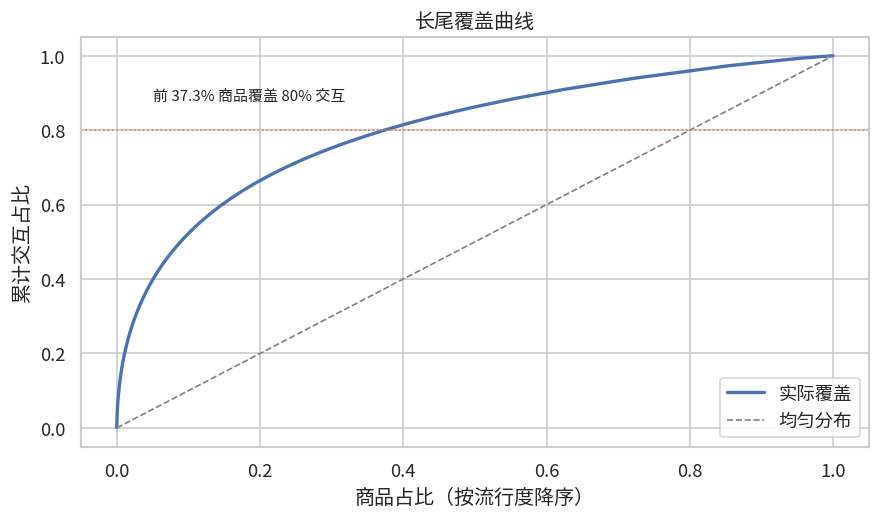

商品 Gini 系数: 0.6037
用户 Gini 系数: 0.5099
前 1% 商品覆盖交互占比: 0.192
后 50% 商品覆盖交互占比: 0.137


In [7]:
def gini(x) -> float:
    x = np.sort(np.asarray(x, dtype=float))
    n = len(x)
    cum = np.cumsum(x)
    return float(2 * np.sum(np.arange(1, n + 1) * x) / (n * cum[-1]) - (n + 1) / n)


pop = item_counts.sort_values(ascending=False).values
cum_share = np.cumsum(pop) / pop.sum()
frac_items = np.arange(1, len(pop) + 1) / len(pop)
k80 = int(np.searchsorted(cum_share, 0.8)) + 1

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.plot(frac_items, cum_share, color="#4C72B0", lw=2, label="实际覆盖")
ax.plot([0, 1], [0, 1], "--", color="gray", lw=1, label="均匀分布")
ax.axhline(0.8, color="#DD8452", ls=":", lw=1)
ax.set_xlabel("商品占比（按流行度降序）")
ax.set_ylabel("累计交互占比")
ax.set_title("长尾覆盖曲线")
ax.legend(loc="lower right")
ax.text(0.05, 0.88, f"前 {k80 / len(pop):.1%} 商品覆盖 80% 交互", fontsize=9)
plt.tight_layout()
plt.savefig(FIG / "03_long_tail.png", bbox_inches="tight", dpi=150)
plt.show()

top1pct = max(int(0.01 * len(pop)) - 1, 0)
print(f"商品 Gini 系数: {gini(pop):.4f}")
print(f"用户 Gini 系数: {gini(user_counts.values):.4f}")
print(f"前 1% 商品覆盖交互占比: {cum_share[top1pct]:.3f}")
print(f"后 50% 商品覆盖交互占比: {1 - cum_share[int(0.5 * len(pop)) - 1]:.3f}")

## 7. 时间分布

检查时间戳范围与按月评分数，识别数据是否集中于某些年份（会影响时间感知划分/推荐的可行性）。

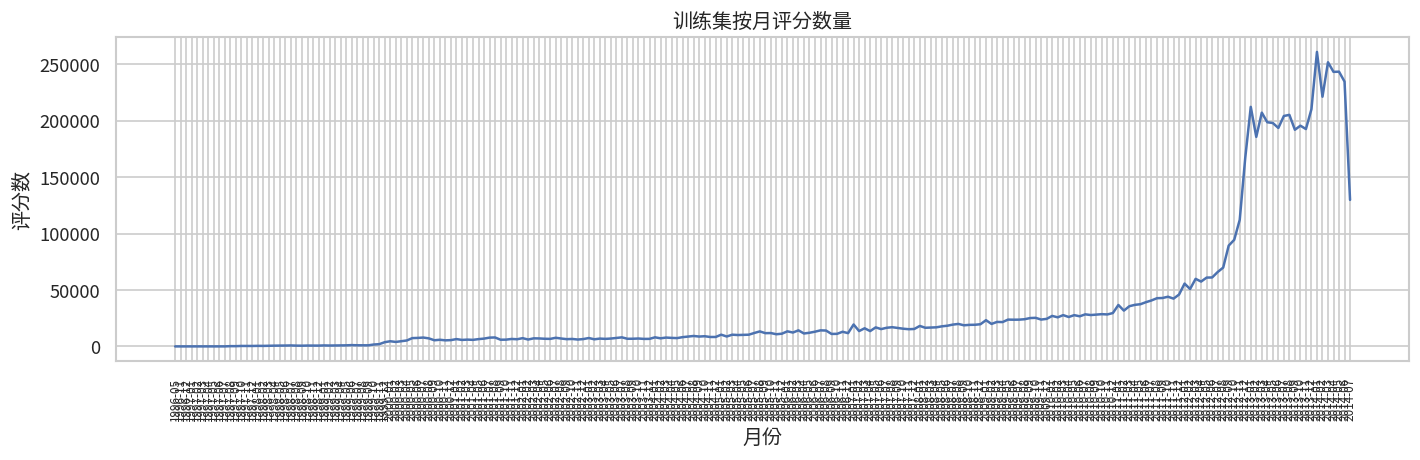

时间范围: 1996-05-20 → 2014-07-23
覆盖月份数: 214


In [8]:
ts = pd.to_datetime(train["timestamp"].dropna().astype("int64"), unit="s")
monthly = ts.dt.to_period("M").value_counts().sort_index()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(monthly.index.astype(str), monthly.values, color="#4C72B0", lw=1.5)
ax.set_title("训练集按月评分数量")
ax.set_xlabel("月份")
ax.set_ylabel("评分数")
ax.tick_params(axis="x", rotation=90, labelsize=7)
plt.tight_layout()
plt.savefig(FIG / "04_monthly_ratings.png", bbox_inches="tight", dpi=150)
plt.show()

print("时间范围:", ts.min().date(), "→", ts.max().date())
print("覆盖月份数:", monthly.size)

## 8. 评论文本与有用性

评论长度影响文本模型的成本；有用性投票分布反映可用的辅助信号。

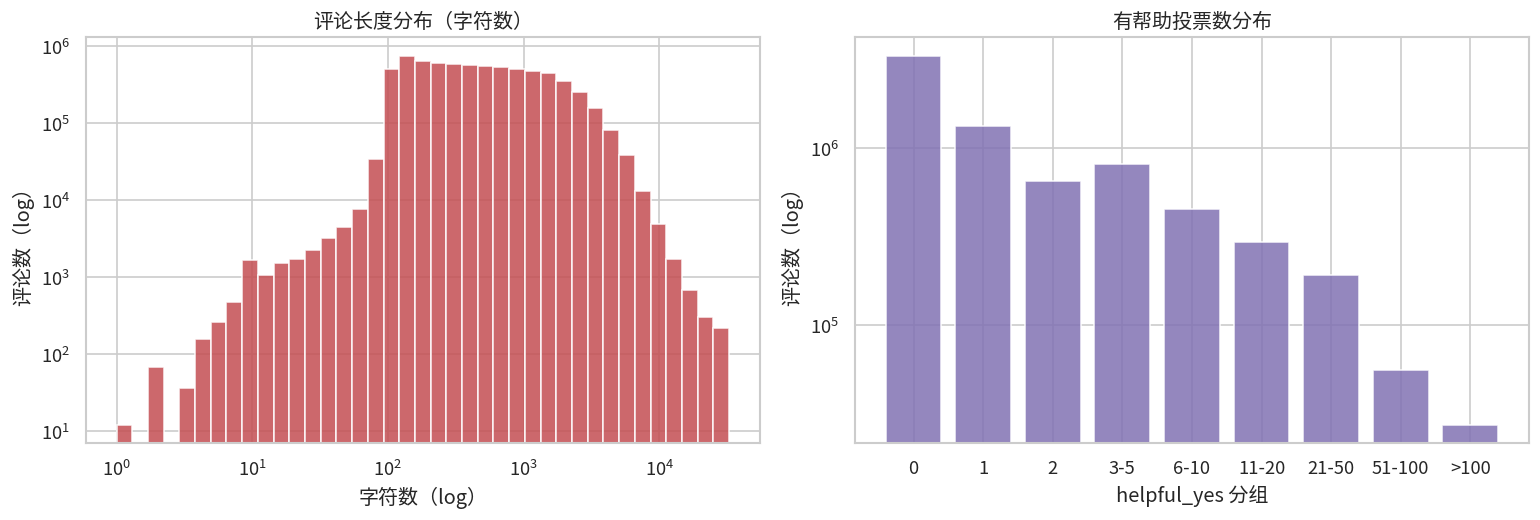

评论长度分位数:


count   7,142,099.0000
mean          817.9000
std         1,035.4000
min             0.0000
50%           429.0000
90%         2,003.0000
99%         4,784.0000
max        32,658.0000
Name: review_text, dtype: Float64

helpful_yes 为 0 的评论占比: 46.56%


In [9]:
lengths = train["review_text"].str.len().dropna()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(lengths, bins=np.logspace(0, np.log10(lengths.max() + 1), 40),
             color="#C44E52", alpha=0.85)
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_title("评论长度分布（字符数）")
axes[0].set_xlabel("字符数（log）")
axes[0].set_ylabel("评论数（log）")

helpful = train["helpful_yes"].fillna(0)
cats = pd.cut(
    helpful,
    bins=[-0.5, 0.5, 1.5, 2.5, 5.5, 10.5, 20.5, 50.5, 100.5, np.inf],
    labels=["0", "1", "2", "3-5", "6-10", "11-20", "21-50", "51-100", ">100"],
)
hcounts = cats.value_counts().sort_index()
axes[1].bar(hcounts.index.astype(str), hcounts.values, color="#8172B3", alpha=0.85)
axes[1].set_yscale("log")
axes[1].set_title("有帮助投票数分布")
axes[1].set_xlabel("helpful_yes 分组")
axes[1].set_ylabel("评论数（log）")

plt.tight_layout()
plt.savefig(FIG / "05_text_helpfulness.png", bbox_inches="tight", dpi=150)
plt.show()

print("评论长度分位数:")
print(lengths.describe(percentiles=[0.5, 0.9, 0.99]).round(1))
print(f"\nhelpful_yes 为 0 的评论占比: {(helpful == 0).mean():.2%}")

## 9. 训练/测试一致性

除评分分布外，检查每用户测试集比例是否接近 20%，并用 KS 检验比较评分分布差异。

评分分布 KS 检验: statistic=0.00124, pvalue=0.0262


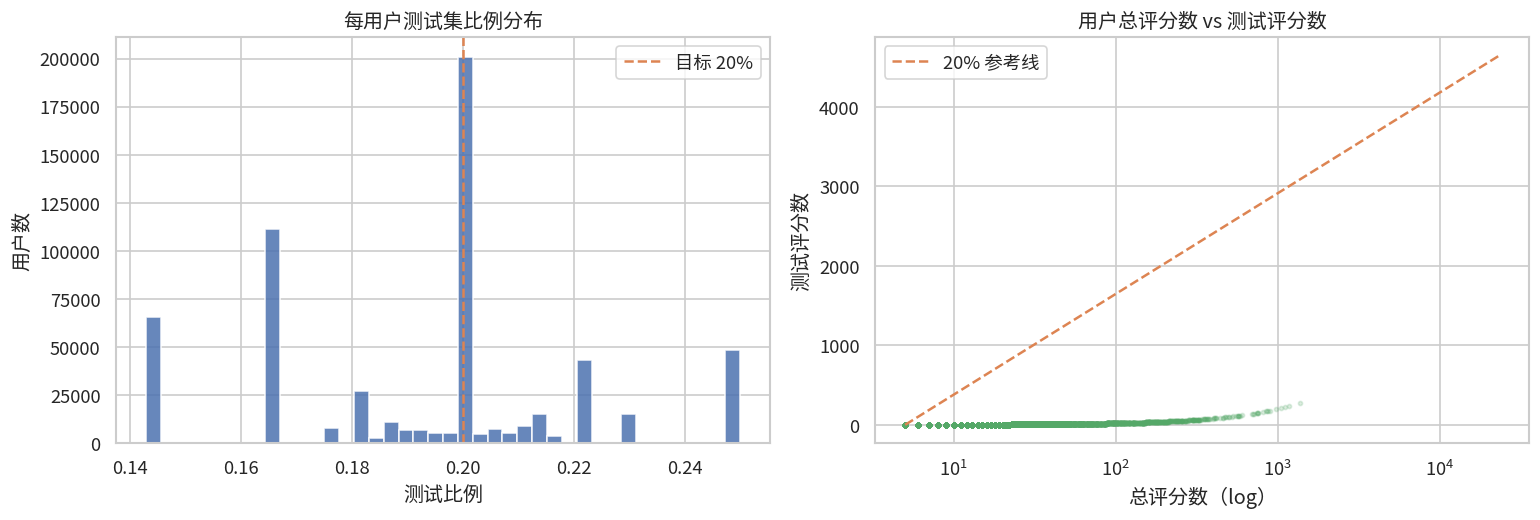

每用户测试比例分位数:
count   603,668.0000
mean          0.1932
std           0.0285
min           0.1429
5%            0.1429
50%           0.2000
95%           0.2500
max           0.2500
dtype: float64


In [10]:
ks = stats.ks_2samp(train.rating.astype(float), test.rating.astype(float))
print(f"评分分布 KS 检验: statistic={ks.statistic:.5f}, pvalue={ks.pvalue:.3g}")

n_all = pd.concat([train[["user_id"]], test[["user_id"]]]).groupby("user_id").size()
n_test = test.groupby("user_id").size().reindex(n_all.index, fill_value=0)
ratio = n_test / n_all

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(ratio, bins=40, color="#4C72B0", alpha=0.85)
axes[0].axvline(0.2, color="#DD8452", ls="--", lw=1.5, label="目标 20%")
axes[0].set_title("每用户测试集比例分布")
axes[0].set_xlabel("测试比例")
axes[0].set_ylabel("用户数")
axes[0].legend()

sample_n = min(len(n_all), 30000)
rng = np.random.default_rng(42)
idx = rng.choice(len(n_all), size=sample_n, replace=False)
axes[1].scatter(n_all.values[idx], n_test.values[idx], s=6, alpha=0.2, color="#55A868")
axes[1].plot(
    [n_all.min(), n_all.max()],
    [0.2 * n_all.min(), 0.2 * n_all.max()],
    color="#DD8452", ls="--", lw=1.5, label="20% 参考线",
)
axes[1].set_xscale("log")
axes[1].set_title("用户总评分数 vs 测试评分数")
axes[1].set_xlabel("总评分数（log）")
axes[1].set_ylabel("测试评分数")
axes[1].legend()

plt.tight_layout()
plt.savefig(FIG / "06_split_consistency.png", bbox_inches="tight", dpi=150)
plt.show()

print("每用户测试比例分位数:")
print(ratio.describe(percentiles=[0.05, 0.5, 0.95]).round(4))

## 10. 评分偏置分解

将评分拆解为全局均值 + 用户偏置 + 商品偏置，是评分预测中最常用的 Baseline 结构。这里观察偏置的分布与幅度。

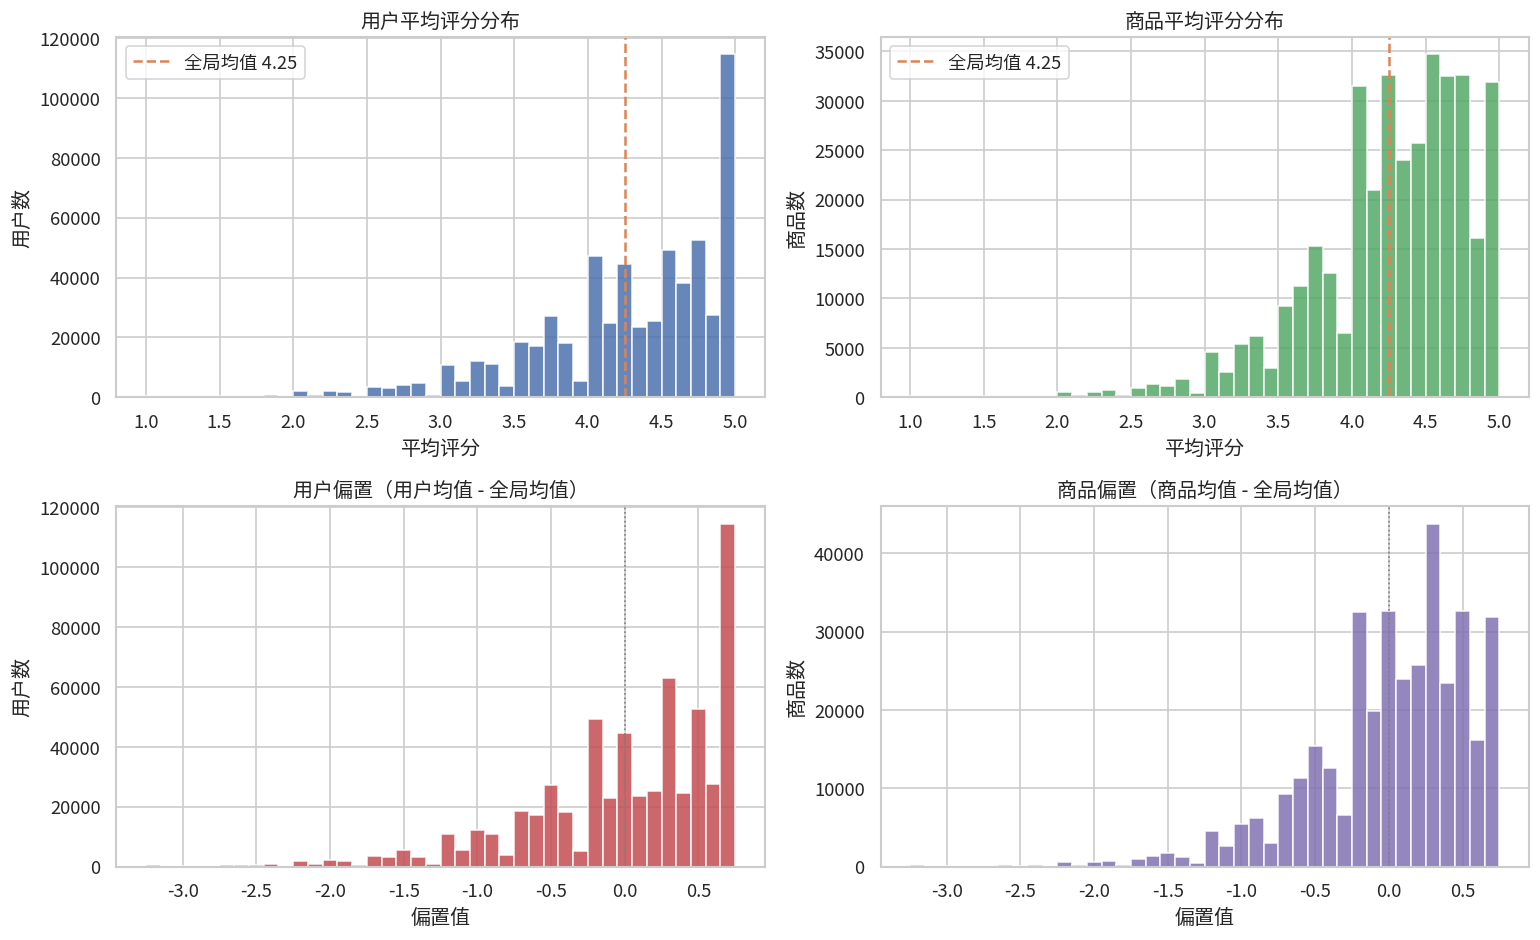

,用户均值,商品均值,用户偏置,商品偏置
count,"603,668.0000","367,965.0000","603,668.0000","367,965.0000"
mean,4.2650,4.2620,0.0150,0.0120
std,0.6650,0.5430,0.6650,0.5430
min,1.0000,1.0000,-3.2500,-3.2500
10%,3.3680,3.5560,-0.8820,-0.6940
50%,4.4000,4.3330,0.1500,0.0830
90%,5.0000,4.8570,0.7500,0.6070
max,5.0000,5.0000,0.7500,0.7500


In [11]:
global_mean = float(train.rating.mean())
user_stats = train.groupby("user_id").agg(user_count=("rating", "size"), user_mean=("rating", "mean"))
item_stats = train.groupby("item_id").agg(item_count=("rating", "size"), item_mean=("rating", "mean"))
user_bias = user_stats["user_mean"] - global_mean
item_bias = item_stats["item_mean"] - global_mean

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
axes[0, 0].hist(user_stats["user_mean"], bins=40, color="#4C72B0", alpha=0.85)
axes[0, 0].axvline(global_mean, color="#DD8452", ls="--", lw=1.5, label=f"全局均值 {global_mean:.2f}")
axes[0, 0].set_title("用户平均评分分布")
axes[0, 0].set_xlabel("平均评分")
axes[0, 0].set_ylabel("用户数")
axes[0, 0].legend()

axes[0, 1].hist(item_stats["item_mean"], bins=40, color="#55A868", alpha=0.85)
axes[0, 1].axvline(global_mean, color="#DD8452", ls="--", lw=1.5, label=f"全局均值 {global_mean:.2f}")
axes[0, 1].set_title("商品平均评分分布")
axes[0, 1].set_xlabel("平均评分")
axes[0, 1].set_ylabel("商品数")
axes[0, 1].legend()

axes[1, 0].hist(user_bias, bins=40, color="#C44E52", alpha=0.85)
axes[1, 0].axvline(0, color="gray", ls=":", lw=1)
axes[1, 0].set_title("用户偏置（用户均值 - 全局均值）")
axes[1, 0].set_xlabel("偏置值")
axes[1, 0].set_ylabel("用户数")

axes[1, 1].hist(item_bias, bins=40, color="#8172B3", alpha=0.85)
axes[1, 1].axvline(0, color="gray", ls=":", lw=1)
axes[1, 1].set_title("商品偏置（商品均值 - 全局均值）")
axes[1, 1].set_xlabel("偏置值")
axes[1, 1].set_ylabel("商品数")

plt.tight_layout()
plt.savefig(FIG / "07_rating_bias.png", bbox_inches="tight", dpi=150)
plt.show()

bias_tbl = pd.DataFrame({
    "用户均值": user_stats["user_mean"].describe(percentiles=[0.1, 0.5, 0.9]),
    "商品均值": item_stats["item_mean"].describe(percentiles=[0.1, 0.5, 0.9]),
    "用户偏置": user_bias.describe(percentiles=[0.1, 0.5, 0.9]),
    "商品偏置": item_bias.describe(percentiles=[0.1, 0.5, 0.9]),
})
display(bias_tbl.round(3))

## 11. 活跃度/流行度与评分的关系

用户越活跃、商品越流行，其平均评分是否更极端或更稳定？用六边形分箱（hexbin）观察密度，避免散点重叠。

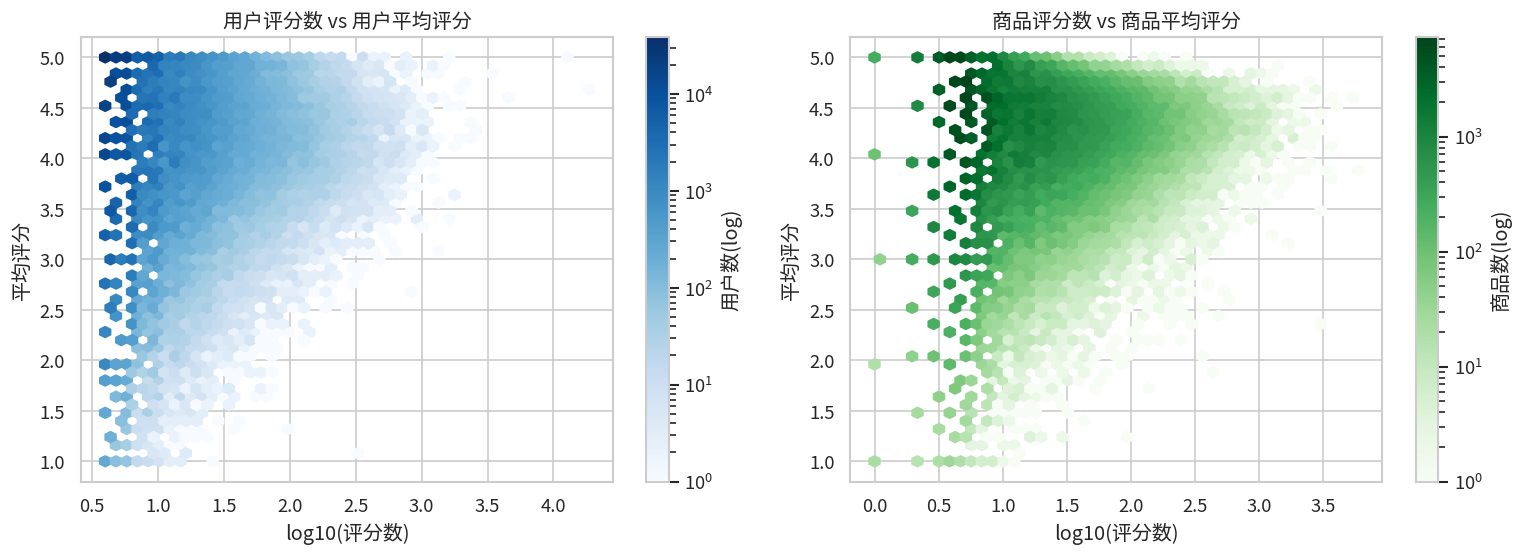

用户评分数 <-> 平均评分 Spearman: rho=-0.0748, p=0
商品评分数 <-> 平均评分 Spearman: rho=-0.0882, p=0


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
hb0 = axes[0].hexbin(np.log10(user_stats["user_count"]), user_stats["user_mean"],
                     gridsize=45, bins="log", cmap="Blues", mincnt=1)
axes[0].set_title("用户评分数 vs 用户平均评分")
axes[0].set_xlabel("log10(评分数)")
axes[0].set_ylabel("平均评分")
fig.colorbar(hb0, ax=axes[0], label="用户数(log)")

hb1 = axes[1].hexbin(np.log10(item_stats["item_count"]), item_stats["item_mean"],
                     gridsize=45, bins="log", cmap="Greens", mincnt=1)
axes[1].set_title("商品评分数 vs 商品平均评分")
axes[1].set_xlabel("log10(评分数)")
axes[1].set_ylabel("平均评分")
fig.colorbar(hb1, ax=axes[1], label="商品数(log)")

plt.tight_layout()
plt.savefig(FIG / "08_activity_vs_rating.png", bbox_inches="tight", dpi=150)
plt.show()

ru = stats.spearmanr(user_stats["user_count"], user_stats["user_mean"])
ri = stats.spearmanr(item_stats["item_count"], item_stats["item_mean"])
print(f"用户评分数 <-> 平均评分 Spearman: rho={ru.statistic:.4f}, p={ru.pvalue:.3g}")
print(f"商品评分数 <-> 平均评分 Spearman: rho={ri.statistic:.4f}, p={ri.pvalue:.3g}")

## 12. 计数 CDF 与测试集覆盖率

CDF 用于判断"大多数用户/商品有多少交互"；覆盖率用于判断测试集商品能否被训练集模型看到，直接影响 Top-N 推荐是否可行。

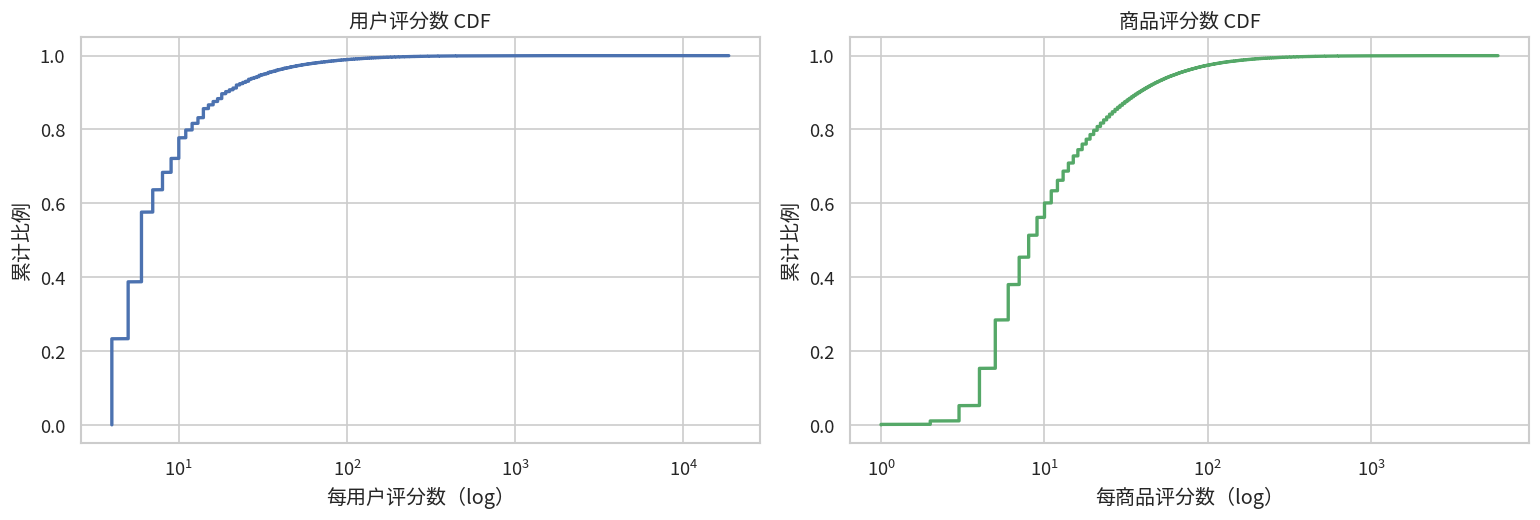

,指标,值
0,测试交互的商品在训练中出现过的比例,100.00%
1,测试商品在训练中出现过的比例,99.99%
2,仅出现在测试集的商品数,17
3,测试用户在训练中出现过的比例,100.00%
4,仅出现在测试集的用户数,0


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, s, label, color in [
    (axes[0], user_counts, "用户", "#4C72B0"),
    (axes[1], item_counts, "商品", "#55A868"),
]:
    x = np.sort(s.values)
    y = np.arange(1, len(x) + 1) / len(x)
    ax.plot(x, y, color=color, lw=2)
    ax.set_xscale("log")
    ax.set_xlabel(f"每{label}评分数（log）")
    ax.set_ylabel("累计比例")
    ax.set_title(f"{label}评分数 CDF")

plt.tight_layout()
plt.savefig(FIG / "09_count_cdf.png", bbox_inches="tight", dpi=150)
plt.show()

train_items = set(train.item_id)
train_users = set(train.user_id)
test_items = set(test.item_id)
test_users = set(test.user_id)

test_row_item_seen = float(test.item_id.isin(train_items).mean())
test_item_seen_ratio = len(test_items & train_items) / len(test_items) if test_items else 0.0
test_user_seen_ratio = len(test_users & train_users) / len(test_users) if test_users else 0.0

coverage = pd.DataFrame({
    "指标": [
        "测试交互的商品在训练中出现过的比例",
        "测试商品在训练中出现过的比例",
        "仅出现在测试集的商品数",
        "测试用户在训练中出现过的比例",
        "仅出现在测试集的用户数",
    ],
    "值": [
        f"{test_row_item_seen:.2%}",
        f"{test_item_seen_ratio:.2%}",
        len(test_items - train_items),
        f"{test_user_seen_ratio:.2%}",
        len(test_users - train_users),
    ],
})
display(coverage)

## 13. 时间趋势与用户生命周期

年度评分量与平均评分反映数据的时间漂移；用户生命周期（首次到末次评分的时间跨度）反映活跃模式，可供时间感知推荐参考。

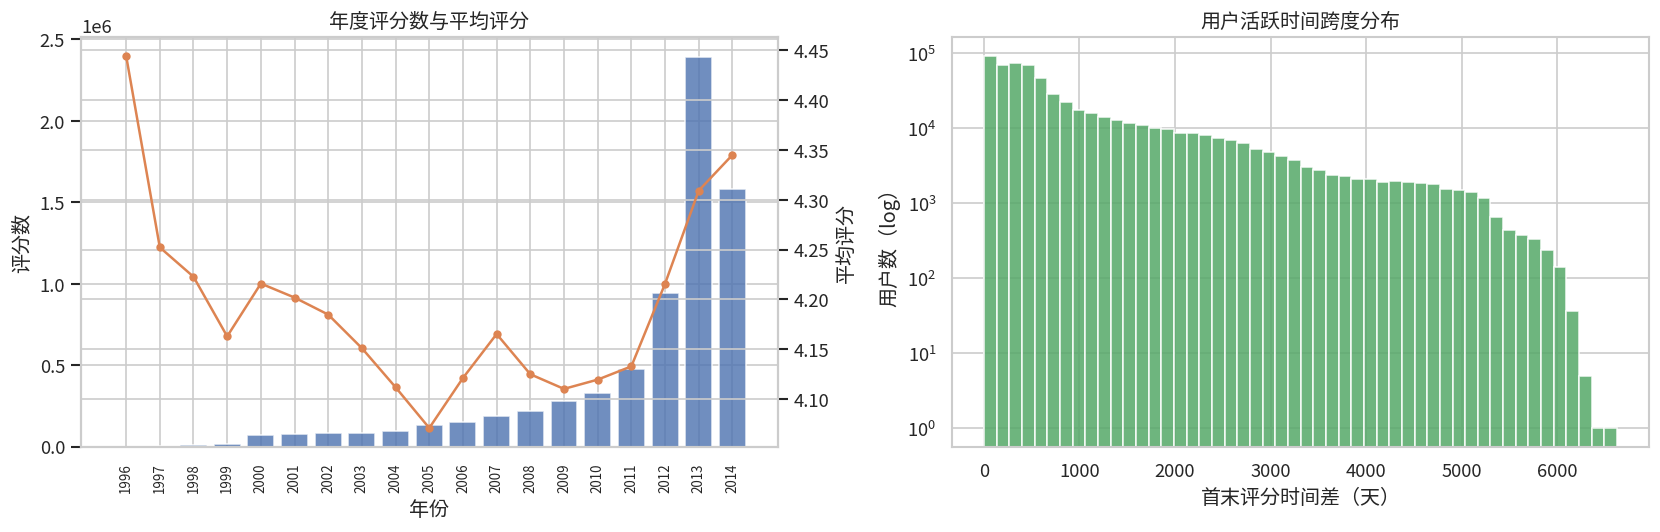

年度评分量（前 5 高）:
year
2013    2394383
2014    1584851
2012     944454
2011     475959
2010     331681
dtype: int64
用户活跃跨度（天）分位数:
count   603,668.0000
mean        973.7000
std       1,105.1000
min           0.0000
50%         520.0000
90%       2,574.0000
99%       4,927.3000
max       6,628.0000
dtype: float64


In [14]:
tmp = pd.DataFrame({
    "year": ts.dt.year.values,
    "rating": train.loc[ts.index, "rating"].values,
})
annual_count = tmp.groupby("year").size()
annual_mean = tmp.groupby("year")["rating"].mean()

grp = train.groupby("user_id")["timestamp"].agg(["min", "max"])
span_days = ((grp["max"] - grp["min"]) / 86400).astype("float64")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
ax1 = axes[0]
ax1.bar(annual_count.index.astype(str), annual_count.values, color="#4C72B0", alpha=0.8)
ax1.set_xlabel("年份")
ax1.set_ylabel("评分数")
ax1.set_title("年度评分数与平均评分")
ax1.tick_params(axis="x", rotation=90, labelsize=8)
ax2 = ax1.twinx()
ax2.plot(annual_mean.index.astype(str), annual_mean.values,
         color="#DD8452", marker="o", ms=4, lw=1.5)
ax2.set_ylabel("平均评分")

axes[1].hist(span_days, bins=50, color="#55A868", alpha=0.85)
axes[1].set_yscale("log")
axes[1].set_title("用户活跃时间跨度分布")
axes[1].set_xlabel("首末评分时间差（天）")
axes[1].set_ylabel("用户数（log）")

plt.tight_layout()
plt.savefig(FIG / "10_temporal_lifecycle.png", bbox_inches="tight", dpi=150)
plt.show()

print("年度评分量（前 5 高）:")
print(annual_count.sort_values(ascending=False).head())
print("用户活跃跨度（天）分位数:")
print(span_days.describe(percentiles=[0.5, 0.9, 0.99]).round(1))

## 14. 评论文本深入分析

评论长度与评分的关系可反映"长评论是否更负面"；高频词则揭示领域主题，为文本增强模型提供依据。

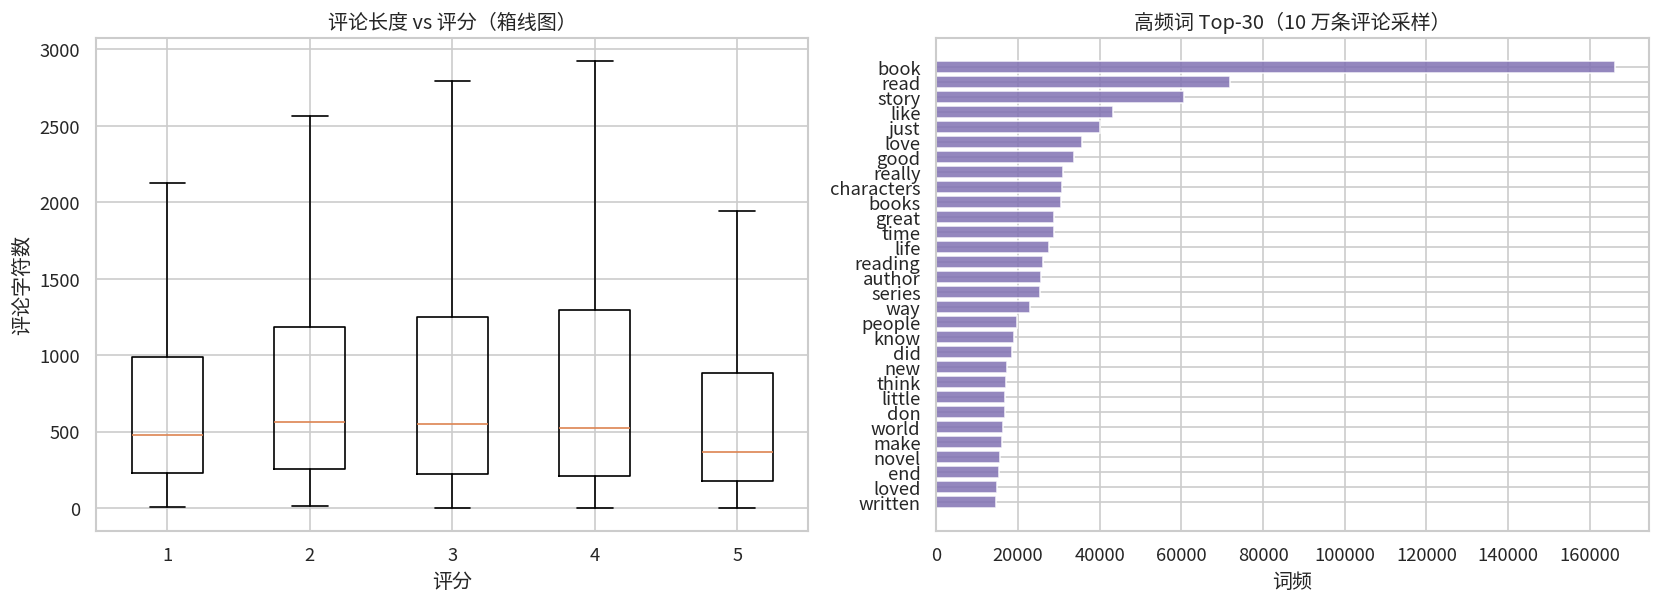

各评分下的评论长度中位数:
rating
1   475.0000
2   565.0000
3   547.0000
4   522.0000
5   366.0000
Name: length, dtype: Float64


,词频
book,166190
read,71851
story,60703
like,43209
just,40053
love,35765
good,33674
really,30892
characters,30677
books,30394


In [15]:
sub_len = pd.DataFrame({
    "rating": train["rating"],
    "length": train["review_text"].str.len(),
}).dropna()
sub_len = sub_len.sample(n=min(120000, len(sub_len)), random_state=42)
data = [sub_len.loc[sub_len.rating == r, "length"].values for r in range(1, 6)]

from sklearn.feature_extraction.text import CountVectorizer

sample_text = train["review_text"].sample(n=min(100000, len(train)), random_state=42)
vec = CountVectorizer(stop_words="english", token_pattern=r"[A-Za-z]{3,}",
                      max_features=20000, min_df=5)
X = vec.fit_transform(sample_text)
freq = np.asarray(X.sum(axis=0)).ravel()
terms = vec.get_feature_names_out()
top_tokens = pd.Series(freq, index=terms).sort_values(ascending=False).head(30)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
axes[0].boxplot(data, tick_labels=[str(r) for r in range(1, 6)], showfliers=False)
axes[0].set_title("评论长度 vs 评分（箱线图）")
axes[0].set_xlabel("评分")
axes[0].set_ylabel("评论字符数")

axes[1].barh(top_tokens.index[::-1], top_tokens.values[::-1],
             color="#8172B3", alpha=0.85)
axes[1].set_title("高频词 Top-30（10 万条评论采样）")
axes[1].set_xlabel("词频")

plt.tight_layout()
plt.savefig(FIG / "11_text_deep.png", bbox_inches="tight", dpi=150)
plt.show()

print("各评分下的评论长度中位数:")
print(sub_len.groupby("rating")["length"].median().round(1))
display(top_tokens.head(15).to_frame("词频"))

## 15. 交互矩阵稀疏模式

随机抽取部分用户与商品，将交互以散点绘制，直观展示矩阵稀疏程度。

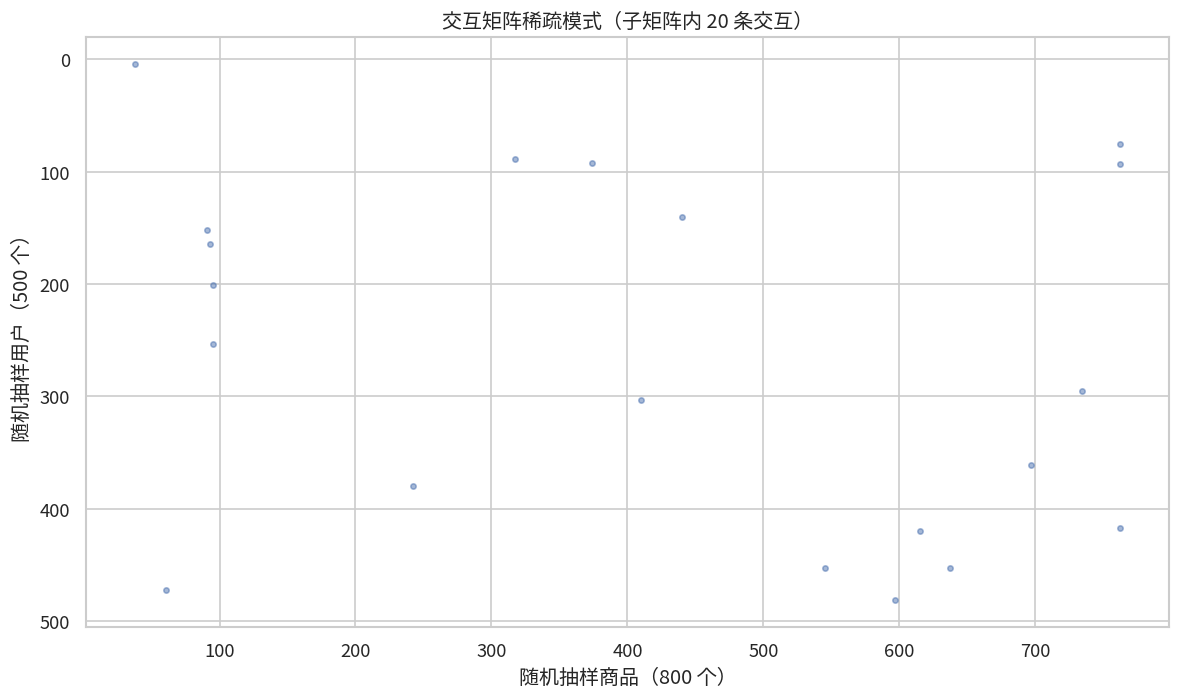

抽样子矩阵密度: 0.0050%（非零比例）


In [16]:
sample_users = pd.Index(user_counts.sample(n=min(500, len(user_counts)), random_state=42).index)
sample_items = pd.Index(item_counts.sample(n=min(800, len(item_counts)), random_state=42).index)

sub_matrix = train[train.user_id.isin(sample_users) & train.item_id.isin(sample_items)]
u_idx = {u: i for i, u in enumerate(sample_users)}
i_idx = {v: i for i, v in enumerate(sample_items)}

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(sub_matrix.item_id.map(i_idx), sub_matrix.user_id.map(u_idx),
           s=10, alpha=0.5, color="#4C72B0")
ax.set_xlabel(f"随机抽样商品（{len(sample_items)} 个）")
ax.set_ylabel(f"随机抽样用户（{len(sample_users)} 个）")
ax.set_title(f"交互矩阵稀疏模式（子矩阵内 {len(sub_matrix)} 条交互）")
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(FIG / "12_sparsity_pattern.png", bbox_inches="tight", dpi=150)
plt.show()

density = len(sub_matrix) / (len(sample_users) * len(sample_items))
print(f"抽样子矩阵密度: {density:.4%}（非零比例）")

## 16. 冷启动与极端值

统计训练集中交互过少的商品/用户，它们会显著影响 Top-N 评估（测试商品可能来自极冷门商品）。

In [17]:
cold_items = int((item_counts < 5).sum())
single_items = int((item_counts == 1).sum())
cold_users = int((user_counts < 5).sum())

cold = pd.DataFrame({
    "指标": [
        "训练集中仅 1 条评分的商品数",
        "训练集中少于 5 条评分的商品数",
        "训练集中少于 5 条评分的用户数",
        "最大单用户评分数",
        "最大单商品评分数",
        "测试集中每个用户的测试商品数(中位数)",
    ],
    "值": [
        single_items,
        cold_items,
        cold_users,
        int(user_counts.max()),
        int(item_counts.max()),
        float(n_test.median()),
    ],
})

display(cold)

,指标,值
0,训练集中仅 1 条评分的商品数,420.0000
1,训练集中少于 5 条评分的商品数,"56,271.0000"
2,训练集中少于 5 条评分的用户数,"140,680.0000"
3,最大单用户评分数,"18,578.0000"
4,最大单商品评分数,"5,946.0000"
5,测试集中每个用户的测试商品数(中位数),2.0000


## 17. 结论与后续建议

以下结论基于上述统计结果，用于指导第二、三步的算法与评估设计。

In [18]:
eda = {
    "dataset": DATASET,
    "records": {"train": int(len(train)), "test": int(len(test))},
    "users": int(train.user_id.nunique()),
    "items": int(train.item_id.nunique()),
    "sparsity": round(sparsity(train), 6),
    "rating_mean": round(float(train.rating.mean()), 4),
    "rating_distribution": {str(k): int(v) for k, v in train.rating.value_counts().sort_index().items()},
    "gini_item": round(gini(item_counts.values), 4),
    "gini_user": round(gini(user_counts.values), 4),
    "ks_statistic": round(float(ks.statistic), 5),
    "cold_items_lt5": cold_items,
    "single_rating_items": single_items,
    "test_row_item_coverage": round(test_row_item_seen, 4),
    "test_item_coverage": round(test_item_seen_ratio, 4),
    "test_items_only": int(len(test_items - train_items)),
    "user_bias_std": round(float(user_bias.std()), 4),
    "item_bias_std": round(float(item_bias.std()), 4),
    "top_tokens": {str(k): int(v) for k, v in top_tokens.head(10).items()},
    "time_range": [str(ts.min().date()), str(ts.max().date())],
    "checks": {
        "missing_core": int(train[["user_id", "item_id", "rating"]].isna().any(axis=1).sum()),
        "duplicates": int(train.duplicated(["user_id", "item_id"]).sum()),
        "leakage_overlap": int(len(leak)),
    },
}
(FIG / "eda_summary.json").write_text(json.dumps(eda, ensure_ascii=False, indent=2), encoding="utf-8")

print("图表输出:")
for p in sorted(FIG.glob("*.png")):
    print(f"  - {p.relative_to(PROJECT)}  ({p.stat().st_size / 1024:.0f} KB)")
print("\n统计摘要:", FIG.relative_to(PROJECT) / "eda_summary.json")
print(f"测试集商品覆盖率: {test_row_item_seen:.2%} | 用户偏置σ={user_bias.std():.3f} | 商品偏置σ={item_bias.std():.3f}")

print("""
关键结论:
1) 数据完整性: 核心字段无缺失、无重复、无非法评分、训练/测试无泄漏，划分可用。
2) 评分偏正: 4-5 星占多数，评分预测需使用带偏置的模型（Baseline / Bias-MF），
   评估时 MAE/RMSE 应同时报告全局均值基线作参照。
3) 长尾显著: 大量商品交互很少，Top-N 推荐与 NDCG 评估需关注冷门商品和冷启动，
   必要时对热门商品做惩罚或使用负采样。
4) 用户活跃度差异大: 以"用户平均"而非全局汇总计算 Precision/Recall 更稳健。
5) 训练/测试同分布: KS 统计量很小、每用户测试比例围绕 20%，说明随机划分合理。
6) 覆盖率: 上方给出测试交互中商品在训练出现过的比例；接近 100% 说明 Top-N 测试商品
   基本都曾出现，冷启动主要影响低频商品排序而非完全不可见。
7) 偏置幅度: 用户/商品偏置标准差见上方，Bias Baseline 可显著降低 MAE，应作为首个基线。
8) 文本可用: 评论文本几乎非空，长度与评分存在关系，适合后续做文本增强或跨媒体模型。
""")

图表输出:
  - experiments/logs/eda/Books/01_rating_distribution.png  (35 KB)
  - experiments/logs/eda/Books/02_activity_distributions.png  (49 KB)
  - experiments/logs/eda/Books/03_long_tail.png  (68 KB)
  - experiments/logs/eda/Books/04_monthly_ratings.png  (82 KB)
  - experiments/logs/eda/Books/05_text_helpfulness.png  (55 KB)
  - experiments/logs/eda/Books/06_split_consistency.png  (97 KB)
  - experiments/logs/eda/Books/07_rating_bias.png  (124 KB)
  - experiments/logs/eda/Books/08_activity_vs_rating.png  (222 KB)
  - experiments/logs/eda/Books/09_count_cdf.png  (45 KB)
  - experiments/logs/eda/Books/10_temporal_lifecycle.png  (99 KB)
  - experiments/logs/eda/Books/11_text_deep.png  (109 KB)
  - experiments/logs/eda/Books/12_sparsity_pattern.png  (50 KB)

统计摘要: experiments/logs/eda/Books/eda_summary.json
测试集商品覆盖率: 100.00% | 用户偏置σ=0.665 | 商品偏置σ=0.543

关键结论:
1) 数据完整性: 核心字段无缺失、无重复、无非法评分、训练/测试无泄漏，划分可用。
2) 评分偏正: 4-5 星占多数，评分预测需使用带偏置的模型（Baseline / Bias-MF），
   评估时 MAE/RMSE 应同时报告全局均值基线作参照。
3) 长